# Course Lead Scoring 2026

Load the data, inspect missing values, and impute them.

- Categorical features: replace missing values with `'NA'`
- Numerical features: replace missing values with `0.0`

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd

URL = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
DATA_PATH = Path("course_lead_scoring_2026.csv")

if not DATA_PATH.exists():
    urlretrieve(URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [2]:
print("Shape:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())

Shape: (5000, 9)

Missing values per column:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [3]:
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = [
    "annual_income",
    "number_of_courses_viewed",
    "interaction_count",
    "lead_score",
    "converted",
]

for col in categorical:
    df[col] = df[col].fillna("NA")

for col in numerical:
    df[col] = df[col].fillna(0.0)

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [5]:
from sklearn.metrics import roc_auc_score

y_train = df_train["converted"]

num_features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income",
]

for col in num_features:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f"{col:25s} AUC = {auc:.4f}")

lead_score                AUC = 0.7882
number_of_courses_viewed  AUC = 0.7230
interaction_count         AUC = 0.7649
annual_income             AUC = 0.6082


In [6]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

features = categorical + num_features

train_dicts = df_train[features].to_dict(orient="records")
val_dicts = df_val[features].to_dict(orient="records")

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_val = df_val["converted"]
y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)
print(f"Validation AUC: {auc:.3f}")

Validation AUC: 0.732


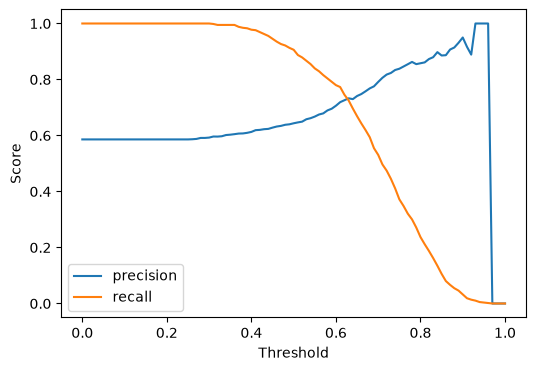

In [7]:
import numpy as np
import matplotlib.pyplot as plt

scores = []
thresholds = np.arange(0.0, 1.01, 0.01)

for t in thresholds:
    actual_positive = y_val == 1
    actual_negative = y_val == 0
    predict_positive = y_pred >= t
    predict_negative = y_pred < t

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    scores.append((t, precision, recall))

df_scores = pd.DataFrame(scores, columns=["threshold", "precision", "recall"])

plt.figure(figsize=(6, 4))
plt.plot(df_scores["threshold"], df_scores["precision"], label="precision")
plt.plot(df_scores["threshold"], df_scores["recall"], label="recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.show()

In [8]:
candidates = df_scores[~((df_scores["precision"] == 0) & (df_scores["recall"] == 0))].copy()
candidates["diff"] = (candidates["precision"] - candidates["recall"]).abs()

best = candidates.loc[candidates["diff"].idxmin()]
print(f"Intersection threshold: {best['threshold']:.2f}")
print(f"precision = {best['precision']:.3f}, recall = {best['recall']:.3f}")

Intersection threshold: 0.63
precision = 0.733, recall = 0.725


In [9]:
df_scores["f1"] = (
    2
    * df_scores["precision"]
    * df_scores["recall"]
    / (df_scores["precision"] + df_scores["recall"]).replace(0, np.nan)
).fillna(0.0)

best_f1 = df_scores.loc[df_scores["f1"].idxmax()]
print(f"Max F1 threshold: {best_f1['threshold']:.2f}")
print(f"F1 = {best_f1['f1']:.3f}")

Max F1 threshold: 0.41
F1 = 0.758


In [10]:
from sklearn.model_selection import KFold


def train(df_train, y_train, C=1.0):
    dicts = df_train[features].to_dict(orient="records")
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    model.fit(X_train, y_train)
    return dv, model


def predict(df, dv, model):
    dicts = df[features].to_dict(orient="records")
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred


kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    dv, model = train(df_train_fold, df_train_fold["converted"].values, C=1.0)
    y_pred_fold = predict(df_val_fold, dv, model)
    auc = roc_auc_score(df_val_fold["converted"].values, y_pred_fold)
    scores.append(auc)

print(f"Mean AUC: {np.mean(scores):.3f}")
print(f"Std AUC: {np.std(scores):.3f}")
print(scores)

Mean AUC: 0.732
Std AUC: 0.007
[0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]


In [11]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
C_values = [0.000001, 0.001, 1]

results = []
for C in C_values:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]

        dv, model = train(df_train_fold, df_train_fold["converted"].values, C=C)
        y_pred_fold = predict(df_val_fold, dv, model)
        auc = roc_auc_score(df_val_fold["converted"].values, y_pred_fold)
        scores.append(auc)

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)
    results.append((C, mean_auc, std_auc))
    print(f"C={C}: mean={mean_auc:.3f}, std={std_auc:.3f}")

results_sorted = sorted(results, key=lambda x: (-x[1], x[2], x[0]))
best_c = results_sorted[0][0]
print(f"Best C: {best_c}")

C=1e-06: mean=0.617, std=0.019


C=0.001: mean=0.749, std=0.010


C=1: mean=0.732, std=0.007
Best C: 0.001
